In [51]:
import cv2
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.figure import Figure

In [4]:
path = Path("../output/tracking_pixels.csv")
df = pd.read_csv(path)

In [37]:
video = Path("../data/tactical/BAR-ATH_tactical-002.mp4")

In [49]:
def get_frame(frame_index, path=video):
    try:
        capture = cv2.VideoCapture(video)
        capture.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
        success, frame = capture.read()
    finally:
        capture.release()
    return frame

In [62]:
def visualize_frame(
    frame_index: int,
    dataframe: pd.DataFrame,
    path: str | Path = video,
    figsize: tuple[int, int] = (24, 8),
) -> Figure:
    image = get_frame(frame_index, path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    positions = dataframe.loc[dataframe["frame"].eq(frame_index)]
    positions = positions.dropna(subset=["pos_x", "pos_y"])
    positions = positions.loc[
        positions["pos_x"].between(0, width, inclusive="left")
        & positions["pos_y"].between(0, height, inclusive="left")
    ]

    teams = sorted(dataframe["team_id"].dropna().unique())
    palette = plt.get_cmap("tab10")

    fig, (original_ax, labelled_ax) = plt.subplots(
        1,
        2,
        figsize=figsize,
        sharex=True,
        sharey=True,
        layout="constrained",
    )

    for ax in (original_ax, labelled_ax):
        ax.imshow(image)
        ax.set_xlim(-0.5, width - 0.5)
        ax.set_ylim(height - 0.5, -0.5)
        ax.axis("off")

    original_ax.set_title(f"Frame {frame_index} — original")
    labelled_ax.set_title(f"Frame {frame_index} — tracking labels")

    for index, team_id in enumerate(teams):
        players = positions.loc[
            positions["entity_type"].eq("player")
            & positions["team_id"].eq(team_id)
        ]

        labelled_ax.scatter(
            players["pos_x"],
            players["pos_y"],
            color=palette(index % 10),
            edgecolors="black",
            s=80,
            label=f"Team {index + 1}: {team_id}",
            zorder=3,
        )

    ball = positions.loc[positions["entity_type"].eq("ball")]
    labelled_ax.scatter(
        ball["pos_x"],
        ball["pos_y"],
        color="yellow",
        edgecolors="black",
        s=65,
        label="Ball",
        zorder=4,
    )

    for entity in positions.itertuples(index=False):
        labelled_ax.annotate(
            entity.entity_id,
            (entity.pos_x, entity.pos_y),
            xytext=(7, 7),
            textcoords="offset points",
            color="white",
            fontsize=9,
            bbox={
                "facecolor": "black",
                "alpha": 0.6,
                "edgecolor": "none",
                "pad": 2,
            },
            clip_on=True,
            zorder=5,
        )

    labelled_ax.legend(loc="upper right", fontsize=8)

    return fig

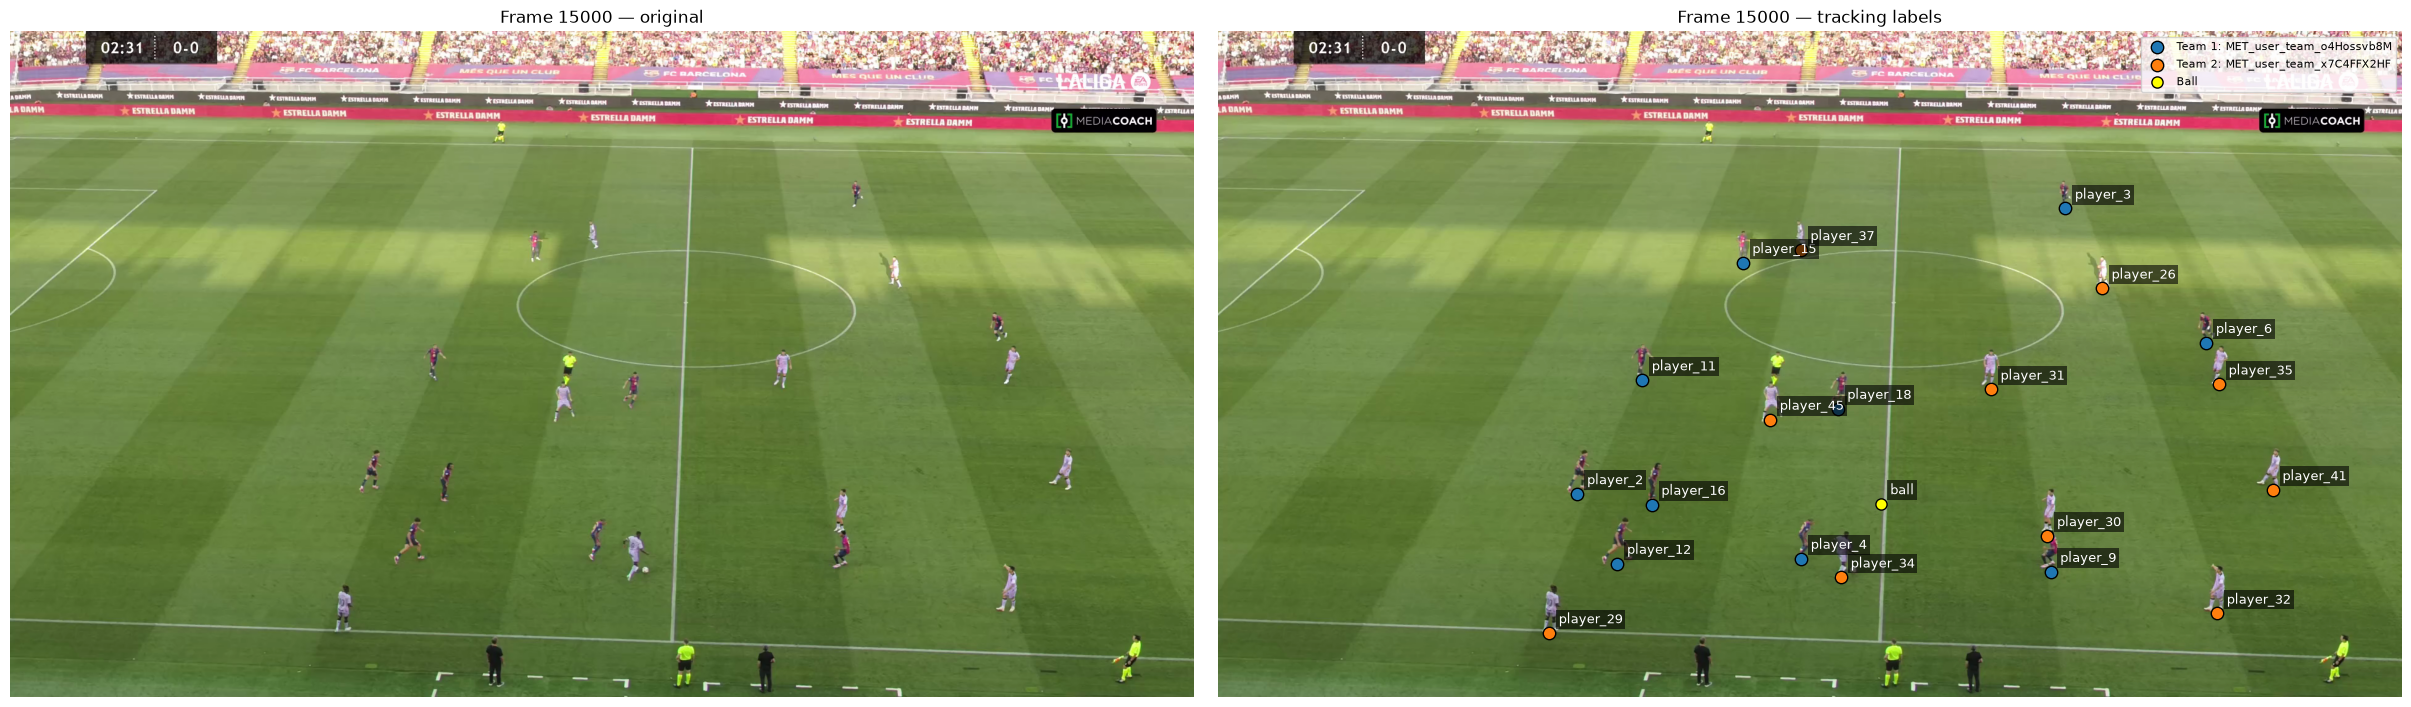

In [65]:
fig = visualize_frame(15000, df, figsize=(24, 12))
plt.show()